# Lab 08 — Model Evaluation, Class Imbalance and Model Selection
## Notebook 01 — In-class Demonstration

### Dataset
**Credit Card Fraud Detection** (`creditcard.csv`)

### Main idea
A classifier can appear excellent when judged by accuracy while performing poorly on the rare class.  
This notebook demonstrates how to evaluate an imbalanced classifier more carefully, investigate thresholds, handle class imbalance, use stratified cross-validation, tune hyperparameters, and keep the final test set untouched until the end.

> Upload `creditcard.csv` to the notebook working directory before running the data-loading cell.

## 1. Imports

`imbalanced-learn` is required for SMOTE. In Google Colab it is usually available. If it is missing, run:

`!pip install imbalanced-learn`

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    auc,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

RANDOM_STATE = 42

## 2. Load the real dataset

The target column is `Class`:
- `0` = legitimate transaction
- `1` = fraudulent transaction

In [5]:
DATA_PATH = Path("creditcard.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "creditcard.csv was not found. Upload the dataset to the notebook working directory."
    )

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
display(df.head())

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Inspect the target distribution

Before fitting a model, check how many observations belong to each class and calculate the percentages.

,Count,Percentage
Class,,
0,49914,99.828
1,86,0.172


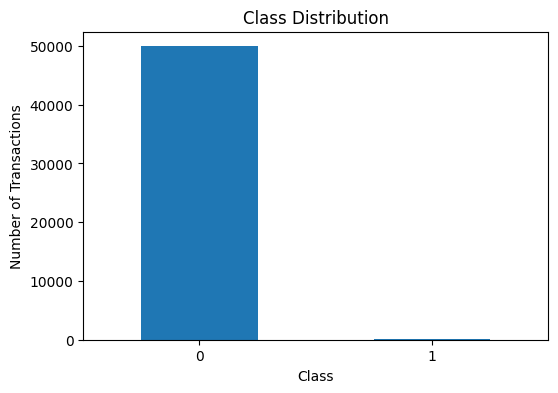

In [26]:
class_counts = df["Class"].value_counts().sort_index()
class_percent = df["Class"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percent
})

display(class_summary)

plt.figure(figsize=(6, 4))
class_counts.plot(kind="bar")
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.show()

### Optional runtime reduction

The original dataset is large. For a classroom demonstration, the following cell keeps a stratified subset while preserving the class proportions.  
If you want to use the full dataset, skip this cell.

In [27]:
if len(df) > 50000:
    df, _ = train_test_split(
        df,
        train_size=50000,
        stratify=df["Class"],
        random_state=RANDOM_STATE
    )
    df = df.reset_index(drop=True)

print("Working dataset shape:", df.shape)
print(df["Class"].value_counts())

Working dataset shape: (50000, 31)
Class
0    49914
1       86
Name: count, dtype: int64


## 4. Hold out the final test set

The final test set must not be used for threshold selection, imbalance experiments, or hyperparameter tuning.

We first create:
- a **development set** for experimentation and model selection;
- a **final test set** that remains untouched until the last section.

In [8]:
X = df.drop(columns="Class")
y = df["Class"]

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    stratify=y_dev,
    random_state=RANDOM_STATE
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

Training: (30000, 30)
Validation: (10000, 30)
Final test: (10000, 30)

Training class proportions:
Class
0    0.998267
1    0.001733
Name: proportion, dtype: float64


## 5. Metric helper

Accuracy is retained as a reference, but the main interpretation will use:
- Precision
- Recall
- F1-score
- MCC
- ROC-AUC
- PR-AUC

The positive class is fraud (`1`).

In [9]:
def evaluate_probabilistic_classifier(model, X_eval, y_eval, threshold=0.50):
    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    precision_curve, recall_curve, _ = precision_recall_curve(y_eval, probabilities)
    pr_auc = auc(recall_curve, precision_curve)

    return {
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "F1": f1_score(y_eval, predictions, zero_division=0),
        "MCC": matthews_corrcoef(y_eval, predictions),
        "ROC-AUC": roc_auc_score(y_eval, probabilities),
        "PR-AUC": pr_auc
    }

## 6. Baseline Logistic Regression

Use a preprocessing pipeline so that scaling is learned from the training data only.

In [10]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

baseline_model.fit(X_train, y_train)

baseline_result = evaluate_probabilistic_classifier(
    baseline_model,
    X_val,
    y_val,
    threshold=0.50
)

display(pd.DataFrame([baseline_result]).round(4))

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.5,0.999,0.7692,0.5882,0.6667,0.6722,0.9531,0.6795


### Inspect the confusion matrix

The key question is not simply, “How many predictions are correct?”  
Look specifically at how many fraudulent transactions are missed.

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


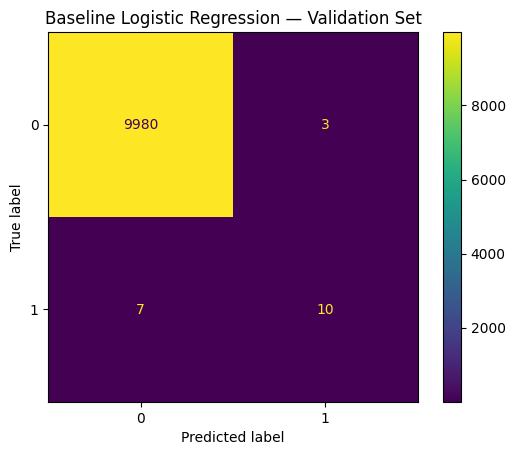

              precision    recall  f1-score   support

           0     0.9993    0.9997    0.9995      9983
           1     0.7692    0.5882    0.6667        17

    accuracy                         0.9990     10000
   macro avg     0.8843    0.7940    0.8331     10000
weighted avg     0.9989    0.9990    0.9989     10000



In [11]:
baseline_val_prob = baseline_model.predict_proba(X_val)[:, 1]
baseline_val_pred = (baseline_val_prob >= 0.50).astype(int)

ConfusionMatrixDisplay.from_predictions(y_val, baseline_val_pred)
plt.title("Baseline Logistic Regression — Validation Set")
plt.show()

print(classification_report(y_val, baseline_val_pred, digits=4, zero_division=0))

## 7. Decision-threshold experiment

The default threshold is 0.50. Compare several thresholds and observe how precision and recall change.

A lower threshold usually predicts more positive cases.  
A higher threshold usually predicts fewer positive cases.

In [12]:
thresholds = [0.10, 0.30, 0.50, 0.70]

threshold_results = [
    evaluate_probabilistic_classifier(
        baseline_model, X_val, y_val, threshold=t
    )
    for t in thresholds
]

threshold_table = pd.DataFrame(threshold_results)
display(threshold_table.round(4))

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/pytho

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.1,0.9988,0.6190,0.7647,0.6842,0.6874,0.9531,0.6795
1,0.3,0.9990,0.7059,0.7059,0.7059,0.7054,0.9531,0.6795
2,0.5,0.9990,0.7692,0.5882,0.6667,0.6722,0.9531,0.6795
3,0.7,0.9991,0.8333,0.5882,0.6897,0.6997,0.9531,0.6795


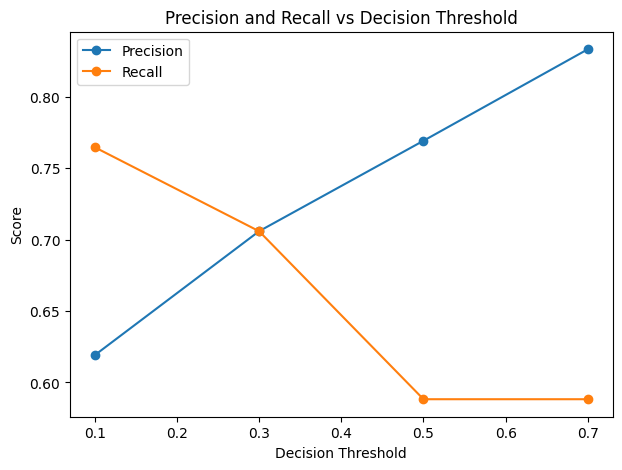

In [13]:
plt.figure(figsize=(7, 5))
plt.plot(
    threshold_table["Threshold"],
    threshold_table["Precision"],
    marker="o",
    label="Precision"
)
plt.plot(
    threshold_table["Threshold"],
    threshold_table["Recall"],
    marker="o",
    label="Recall"
)
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Decision Threshold")
plt.legend()
plt.show()

## 8. ROC curve and Precision–Recall curve

Both curves use the model's continuous scores rather than one fixed decision threshold.

For a rare positive class, the Precision–Recall curve is especially informative because it focuses directly on the quality of positive predictions.

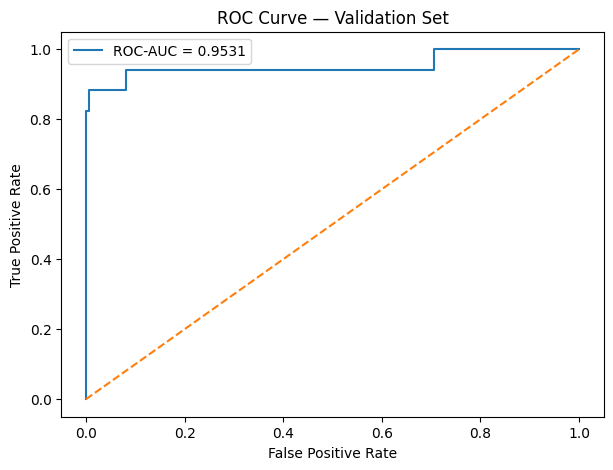

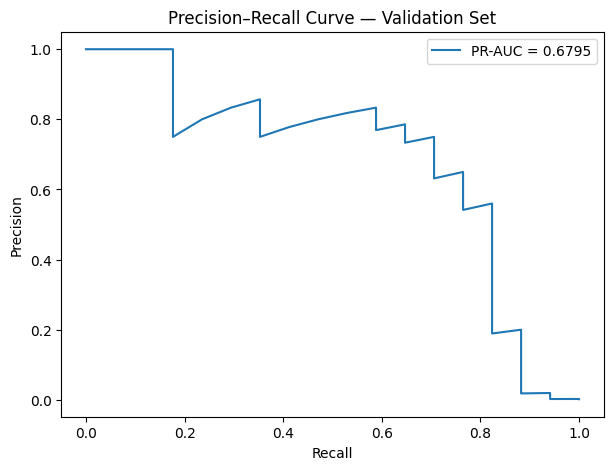

In [14]:
fpr, tpr, _ = roc_curve(y_val, baseline_val_prob)
roc_auc_value = roc_auc_score(y_val, baseline_val_prob)

precision_curve, recall_curve, _ = precision_recall_curve(y_val, baseline_val_prob)
pr_auc_value = auc(recall_curve, precision_curve)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc_value:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Validation Set")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc_value:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Validation Set")
plt.legend()
plt.show()

# Part B — Handling Class Imbalance

We will compare three approaches using the **same training and validation data**:

1. Baseline Logistic Regression
2. Logistic Regression with `class_weight="balanced"`
3. Logistic Regression trained with SMOTE inside an imbalanced-learn pipeline

The validation set keeps its original class distribution.

## 9. Cost-sensitive classification with class weights

In [15]:
weighted_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

weighted_model.fit(X_train, y_train)

weighted_result = evaluate_probabilistic_classifier(
    weighted_model,
    X_val,
    y_val,
    threshold=0.50
)

display(pd.DataFrame([weighted_result]).round(4))

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.5,0.9814,0.0711,0.8235,0.1308,0.2387,0.9036,0.6933


## 10. SMOTE

SMOTE creates synthetic minority-class training samples.

The important rule is:

**SMOTE must be learned from training data only.**

Using an `imblearn` pipeline also allows SMOTE to be applied correctly inside cross-validation later.

In [16]:
smote_model = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

smote_model.fit(X_train, y_train)

smote_result = evaluate_probabilistic_classifier(
    smote_model,
    X_val,
    y_val,
    threshold=0.50
)

display(pd.DataFrame([smote_result]).round(4))

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/li

,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.5,0.9816,0.0718,0.8235,0.1321,0.24,0.9014,0.6888


## 11. Compare the imbalance strategies

Do not select the method from accuracy alone.  
Pay attention to the trade-off between precision, recall, F1, MCC, ROC-AUC and PR-AUC.

In [17]:
comparison = pd.DataFrame([
    {"Method": "Baseline", **baseline_result},
    {"Method": "Class Weight", **weighted_result},
    {"Method": "SMOTE", **smote_result}
])

display(
    comparison[
        ["Method", "Accuracy", "Precision", "Recall", "F1", "MCC", "ROC-AUC", "PR-AUC"]
    ].round(4)
)

,Method,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,Baseline,0.9990,0.7692,0.5882,0.6667,0.6722,0.9531,0.6795
1,Class Weight,0.9814,0.0711,0.8235,0.1308,0.2387,0.9036,0.6933
2,SMOTE,0.9816,0.0718,0.8235,0.1321,0.2400,0.9014,0.6888


# Part C — Validation and Model Selection

## 12. Stratified k-fold cross-validation

The final test set is still untouched.

`StratifiedKFold` keeps approximately the same class proportions in each fold.

In [18]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision"
}

cv_scores = cross_validate(
    weighted_model,
    X_dev,
    y_dev,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
        "Average Precision"
    ],
    "Mean CV Score": [
        cv_scores["test_accuracy"].mean(),
        cv_scores["test_precision"].mean(),
        cv_scores["test_recall"].mean(),
        cv_scores["test_f1"].mean(),
        cv_scores["test_roc_auc"].mean(),
        cv_scores["test_average_precision"].mean()
    ],
    "Std": [
        cv_scores["test_accuracy"].std(),
        cv_scores["test_precision"].std(),
        cv_scores["test_recall"].std(),
        cv_scores["test_f1"].std(),
        cv_scores["test_roc_auc"].std(),
        cv_scores["test_average_precision"].std()
    ]
})

display(cv_summary.round(4))

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

,Metric,Mean CV Score,Std
0,Accuracy,0.9747,0.0050
1,Precision,0.0583,0.0112
2,Recall,0.8681,0.0869
3,F1,0.1089,0.0196
4,ROC-AUC,0.9413,0.0509
5,Average Precision,0.7563,0.1364


## 13. Grid Search

Tune Logistic Regression regularization strength `C` and compare normal versus balanced class weighting.

The search is performed only on the development data.  
Here, **average precision** is used as the model-selection score because the positive class is rare.

In [19]:
search_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

grid = GridSearchCV(
    estimator=search_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_dev, y_dev)

print("Best parameters:", grid.best_params_)
print("Best mean CV average precision:", round(grid.best_score_, 4))

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': None}
Best mean CV average precision: 0.7953


/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_features

In [20]:
grid_results = pd.DataFrame(grid.cv_results_)

display(
    grid_results[
        [
            "param_classifier__C",
            "param_classifier__class_weight",
            "mean_test_score",
            "std_test_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").head(10)
)

,param_classifier__C,param_classifier__class_weight,mean_test_score,std_test_score,rank_test_score
2,0.10,None,0.795270,0.105250,1
0,0.01,None,0.789871,0.120026,2
4,1.00,None,0.782755,0.123311,3
6,10.00,None,0.780887,0.123186,4
5,1.00,balanced,0.756345,0.136379,5
7,10.00,balanced,0.753916,0.137772,6
3,0.10,balanced,0.737312,0.140837,7
1,0.01,balanced,0.720449,0.145206,8


# Part D — Final Test Evaluation

The model and hyperparameters have now been selected using development data and cross-validation.

Only now do we evaluate the untouched final test set.

In [21]:
final_model = grid.best_estimator_

final_result = evaluate_probabilistic_classifier(
    final_model,
    X_test,
    y_test,
    threshold=0.50
)

display(pd.DataFrame([final_result]).round(4))

/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,Threshold,Accuracy,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
0,0.5,0.9994,0.8667,0.7647,0.8125,0.8138,0.9992,0.8414


/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/asirigawesha/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


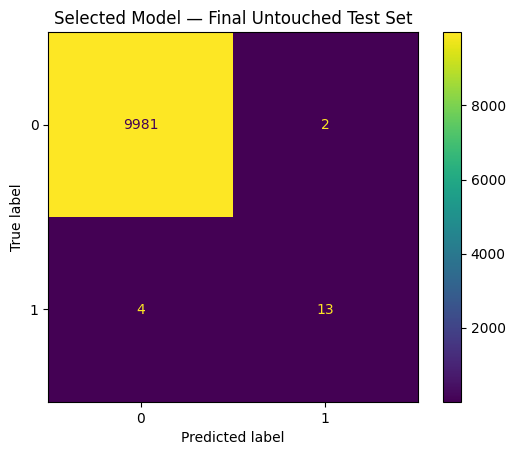

              precision    recall  f1-score   support

           0     0.9996    0.9998    0.9997      9983
           1     0.8667    0.7647    0.8125        17

    accuracy                         0.9994     10000
   macro avg     0.9331    0.8823    0.9061     10000
weighted avg     0.9994    0.9994    0.9994     10000



In [22]:
final_prob = final_model.predict_proba(X_test)[:, 1]
final_pred = (final_prob >= 0.50).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, final_pred)
plt.title("Selected Model — Final Untouched Test Set")
plt.show()

print(classification_report(y_test, final_pred, digits=4, zero_division=0))

# Final Takeaways

- Accuracy alone can be misleading when the positive class is rare.
- Precision and recall describe different error trade-offs.
- Changing the decision threshold changes the balance between false positives and false negatives.
- ROC-AUC and PR-AUC evaluate ranking behaviour across thresholds; PR analysis is especially useful for rare positives.
- Class weighting changes the cost of mistakes without changing the dataset.
- SMOTE changes the training distribution by creating synthetic minority samples.
- Resampling must never be performed on the final test set.
- Stratified cross-validation gives a more stable comparison than relying on one split.
- Hyperparameters should be selected using validation/CV, not final test performance.
- Data-dependent preprocessing should remain inside a pipeline.
- The final test set should be used only after all modelling choices are fixed.